# BOAS: sleep-stage boundaries and physiological antecedents

This notebook follows the project from the released Bitbrain labels to the paired correction experiment and the separate future-boundary task. The published comparison is offline. The results are internal BOAS development estimates, with a boundary gain and a remaining-epoch cost.

## Load the included evidence

Run `python -m pip install -e ".[notebook]"` from the repository root. The default exploration uses compact included predictions; no EDF download is required.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from boas_transition.data import read_archive

ROOT = Path.cwd()
if not (ROOT / 'results').exists():
    ROOT = ROOT.parent
RESULTS = ROOT / 'results'
plt.rcParams.update({'font.size': 11, 'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
BASELINE, PROPOSED = '#607F8D', '#B15D37'
staging = read_archive(RESULTS / 'staging_predictions.npz')
metrics = pd.read_csv(RESULTS / 'staging_metrics.csv').set_index('model')
assert len(staging) == 114611
assert staging.groupby('pid')['fold'].nunique().max() == 1
display(metrics.loc[['Bitbrain','offline','current_past','context_only']].round(4))

,accuracy,non_boundary_accuracy,macro_f1,exact_error,near_error,stable_error,changed_fraction
model,,,,,,,
Bitbrain,0.8672,0.8979,0.7189,0.4634,0.3963,0.0407,0.0000
offline,0.8685,0.8923,0.7442,0.3882,0.3563,0.0498,0.0493
current_past,0.8688,0.8935,0.7421,0.3971,0.3606,0.0488,0.0392
context_only,0.8672,0.8977,0.7218,0.4613,0.3949,0.0412,0.0042


## The boundary problem

A boundary is the first 30-second epoch whose human-consensus stage changes. The horizontal axis below uses unsigned distance, and 10+ combines epochs at least five minutes away.

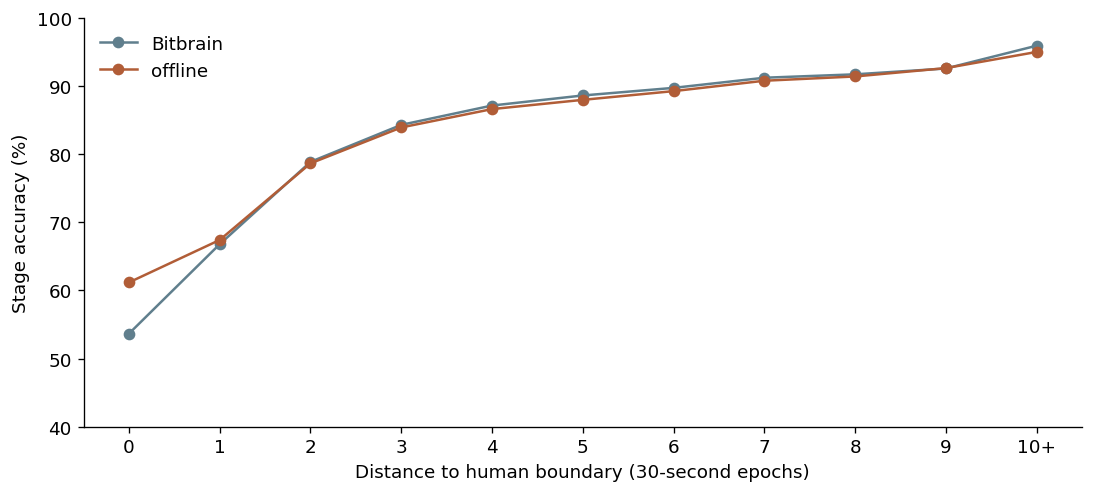

In [2]:
MODEL = 'offline'
distance = staging.distance_to_human_transition.to_numpy()
bins = np.minimum(distance, 10)
truth = staging.stage_hum.to_numpy()
fig, ax = plt.subplots(figsize=(9,4), constrained_layout=True)
for label, column, color in [('Bitbrain','stage_ai_headband',BASELINE), (MODEL,'prediction_'+MODEL,PROPOSED)]:
    values = [100*np.mean(staging[column].to_numpy()[bins==i] == truth[bins==i]) for i in range(11)]
    ax.plot(range(11), values, 'o-', color=color, label=label)
ax.set_xticks(range(11), [*map(str,range(10)), '10+'])
ax.set(xlabel='Distance to human boundary (30-second epochs)', ylabel='Stage accuracy (%)', ylim=(40,100))
ax.legend(frameon=False); plt.show()

## Compare benefit and cost

Exact boundaries and the remaining epochs partition the paired population. The ±30-second and stable subsets are additional, overlapping views. Similar global point estimates do not establish noninferiority.

In [3]:
baseline = metrics.loc['Bitbrain']
proposed = metrics.loc[MODEL]
comparison = pd.DataFrame({
    'Bitbrain': [baseline.accuracy,1-baseline.exact_error,baseline.non_boundary_accuracy,1-baseline.stable_error],
    MODEL: [proposed.accuracy,1-proposed.exact_error,proposed.non_boundary_accuracy,1-proposed.stable_error]
}, index=['Whole night','Exact boundary','Remaining epochs','Stable periods'])
display((comparison*100).round(2))
intervals = pd.read_csv(RESULTS/'staging_intervals.csv')
display(intervals.loc[intervals.model.eq(MODEL)].round(4))

,Bitbrain,offline
Whole night,86.72,86.85
Exact boundary,53.66,61.18
Remaining epochs,89.79,89.23
Stable periods,95.93,95.02


,model,reference,metric,difference,ci_low,ci_high
0,offline,Bitbrain,accuracy,0.0013,-0.0043,0.0058
1,offline,Bitbrain,non_boundary_accuracy,-0.0056,-0.0118,-0.0006
2,offline,Bitbrain,exact_error,-0.0752,-0.0851,-0.0653
3,offline,Bitbrain,near_error,-0.0399,-0.0459,-0.0340
4,offline,Bitbrain,stable_error,0.0091,0.0031,0.0169


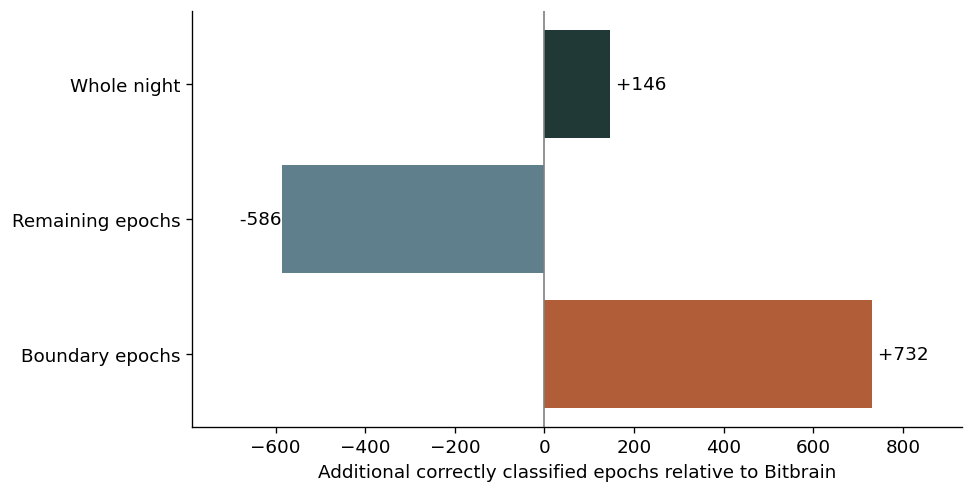

In [4]:
boundary = staging.human_transition.to_numpy(bool)
difference = (staging['prediction_'+MODEL].to_numpy()==truth).astype(int) - (staging.stage_ai_headband.to_numpy()==truth).astype(int)
accounting = pd.Series({'Boundary epochs': difference[boundary].sum(), 'Remaining epochs': difference[~boundary].sum(), 'Whole night': difference.sum()})
fig, ax = plt.subplots(figsize=(8,4), constrained_layout=True)
ax.barh(accounting.index, accounting.values, color=[PROPOSED,BASELINE,'#203936'])
ax.axvline(0,color='gray',linewidth=1)
ax.set_xlabel('Additional correctly classified epochs relative to Bitbrain')
ax.set_xlim(accounting.min()-200, accounting.max()+200)
for i, value in enumerate(accounting):
    ax.text(value, i, f' {value:+d}', va='center', ha='left' if value>=0 else 'right')
plt.show()

## Inspect a particular transition

Change `MINIMUM_EPOCHS` to include sparse cases. These subgroup results are descriptive; small counts should not be interpreted as stable estimates.

In [5]:
MINIMUM_EPOCHS = 200
directed = pd.read_csv(RESULTS/'directed_transitions.csv')
selected = directed.loc[directed.epochs >= MINIMUM_EPOCHS].copy()
selected['accuracy_change_pp'] = 100*(selected[MODEL+'_accuracy']-selected.Bitbrain_accuracy)
display(selected[['transition','epochs','participants','Bitbrain_accuracy',MODEL+'_accuracy','accuracy_change_pp']].round(3))

,transition,epochs,participants,Bitbrain_accuracy,offline_accuracy,accuracy_change_pp
0,Wake→N1,1975,100,0.361,0.546,18.532
1,Wake→N2,249,78,0.542,0.446,-9.639
3,N1→Wake,532,83,0.720,0.744,2.444
4,N1→N2,1996,100,0.762,0.721,-4.108
7,N2→Wake,1322,100,0.556,0.723,16.717
8,N2→N1,536,91,0.118,0.274,15.672
9,N2→N3,861,77,0.369,0.530,16.028
10,N2→REM,546,100,0.641,0.683,4.212
13,N3→N2,827,77,0.669,0.591,-7.739
14,REM→Wake,342,87,0.444,0.614,16.959


## Examine antecedent physiology

Change the transition and feature. Measurements are compared with stable controls of the same origin stage and night. The plotted time is the **end** of the measurement window: −30 s means a 30-second gap before the labelled boundary. Whole-night standardisation is descriptive and is not used by the classifier.

,lead_seconds,effect_sd,ci_low,ci_high,participants,events
279,0,0.883,0.746,1.033,100,565
261,30,0.765,0.649,0.889,99,507
243,90,0.475,0.361,0.597,99,453
225,210,0.166,0.046,0.293,97,370


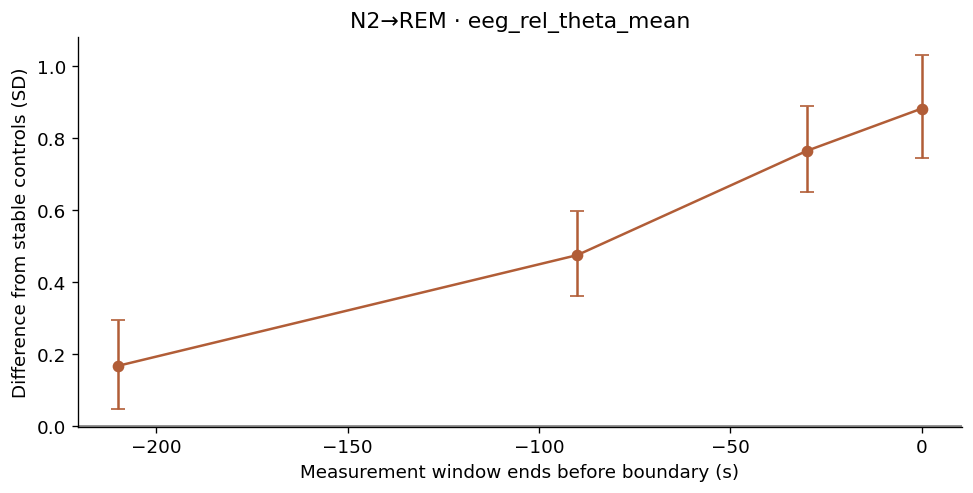

In [6]:
TRANSITION = 'N2→REM'
FEATURE = 'eeg_rel_theta_mean'
effects = pd.read_csv(RESULTS/'physiology_effects.csv')
effect = effects.loc[effects.pair.eq(TRANSITION) & effects.feature.eq(FEATURE)].sort_values('lead_seconds')
assert not effect.empty, 'Choose an available transition and feature.'
display(effect[['lead_seconds','effect_sd','ci_low','ci_high','participants','events']].round(3))
fig, ax = plt.subplots(figsize=(8,4), constrained_layout=True)
ax.errorbar(-effect.lead_seconds, effect.effect_sd, yerr=[effect.effect_sd-effect.ci_low, effect.ci_high-effect.effect_sd], fmt='o-', capsize=4, color=PROPOSED)
ax.axhline(0,color='gray',linewidth=1)
ax.set(title=TRANSITION+' · '+FEATURE, xlabel='Measurement window ends before boundary (s)', ylabel='Difference from stable controls (SD)')
plt.show()

## Predict a future boundary

These are event-prediction metrics, not stage accuracy. The signals-only model receives EEG, pulse, movement and elapsed time without Bitbrain stages. The combined model's upstream Bitbrain context may itself use later information.

,model,n,prevalence,auroc,average_precision,brier,lead_seconds
0,context,114476,0.0855,0.6638,0.1862,0.0748,30
1,combined,114476,0.0855,0.7413,0.2471,0.0716,30
2,physiology,114476,0.0855,0.7273,0.2303,0.0725,30


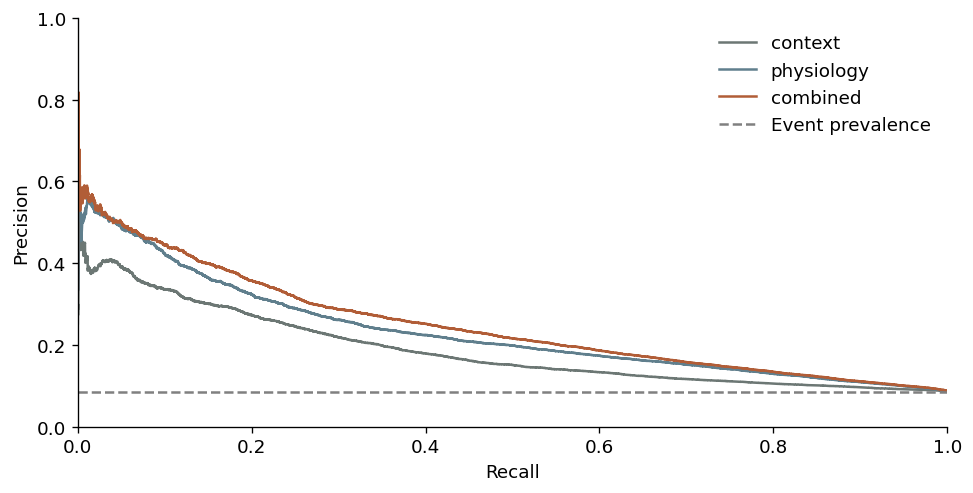

In [7]:
from sklearn.metrics import precision_recall_curve
forecast = read_archive(RESULTS/'forecast_predictions.npz')
display(pd.read_csv(RESULTS/'forecast_metrics.csv').round(4))
fig, ax = plt.subplots(figsize=(8,4), constrained_layout=True)
for name, color in [('context','#6C7774'),('physiology',BASELINE),('combined',PROPOSED)]:
    precision, recall, _ = precision_recall_curve(forecast.future_boundary_30s, forecast[name+'_probability'])
    ax.plot(recall,precision,color=color,label=name)
ax.axhline(forecast.future_boundary_30s.mean(),color='gray',linestyle='--',label='Event prevalence')
ax.set(xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1))
ax.legend(frameon=False); plt.show()

## Optional per-night signal features

After extraction, select a night and time range. Missing pulse measures remain missing. This cell is skipped when the feature cache is absent.

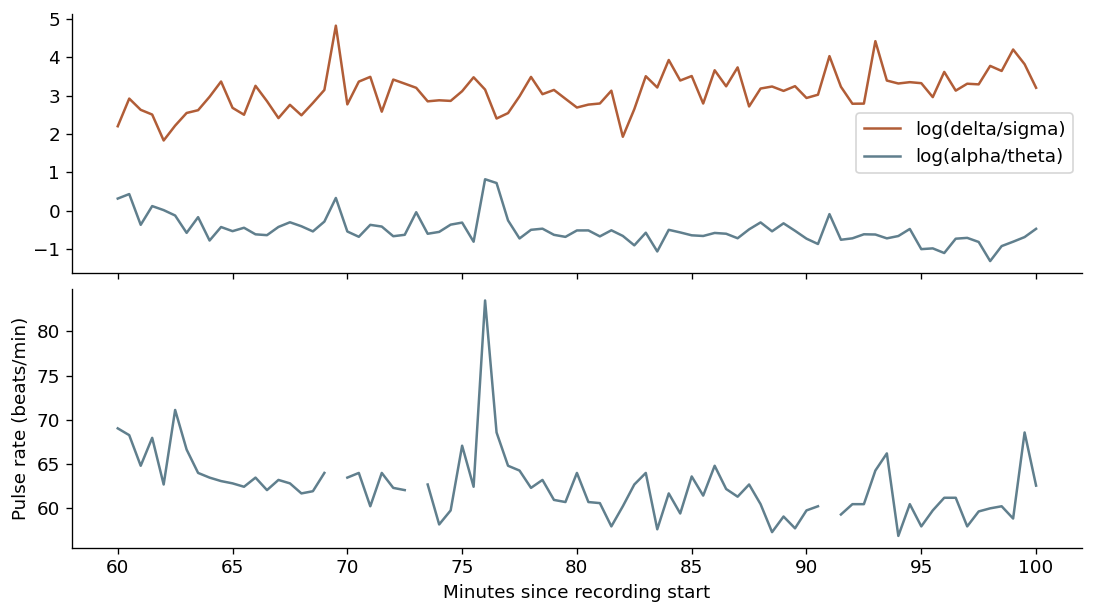

In [8]:
NIGHT = 'sub-100'
START_MINUTE, END_MINUTE = 60, 100
feature_path = ROOT/'data/features/epoch_features.csv.gz'
if feature_path.exists():
    features = pd.read_csv(feature_path)
    night = features.loc[features.participant_id.eq(NIGHT) & features.onset.between(START_MINUTE*60,END_MINUTE*60)]
    fig, axes = plt.subplots(2,1,figsize=(9,5),sharex=True,constrained_layout=True)
    axes[0].plot(night.onset/60,night.eeg_log_delta_sigma_mean,color=PROPOSED,label='log(delta/sigma)')
    axes[0].plot(night.onset/60,night.eeg_log_alpha_theta_mean,color=BASELINE,label='log(alpha/theta)'); axes[0].legend()
    axes[1].plot(night.onset/60,night.ppg_hr,color=BASELINE); axes[1].set(xlabel='Minutes since recording start',ylabel='Pulse rate (beats/min)')
    plt.show()
else:
    print('Run download_data.py and extract_features.py to enable per-night signal exploration.')

## Interpretation

The primary gain is concentrated at human-labelled boundaries. The global point estimate remains close to Bitbrain, but stable and remaining-epoch costs and the global interval prevent a claim of validated product superiority. BOAS is a development dataset; the combined system needs external evaluation with a frozen upstream classifier. Morphology and autonomic features are predictive candidates rather than validated physiological biomarkers.

The [methods](../docs/methods.md), [evidence](../docs/evidence.md) and [reproducibility guide](../docs/reproducibility.md) describe the assumptions and code.